# Analisis Buka Kafe dengan GeoPandas

**Mata Kuliah:** Computer Graphics (AFL 2), Universitas Ciputra Surabaya
**Tim:** Filemon Jose Hagen, Hafizd Dharma Saputra Hardiono

Notebook ini mengerjakan analisis yang sama dengan `analisis_buka_kafe.ipynb`, tetapi memakai alur GIS dari materi kelas:

**create → cek CRS → `to_crs("EPSG:32749")` → `buffer` → `sjoin` → ringkas (`groupby`)**

Ditambah materi grafika 2D: model titik/garis/poligon, transformasi matriks homogen (translasi, rotasi, skala, komposit), *clipping*, *compositing* (transparansi), dan animasi.

Hasil angkanya sama dengan pipeline utama (`scripts/gis_pipeline.py`), sehingga web peta dan notebook ini saling konsisten.

In [1]:
%pip install -q -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 0. Persiapan

In [2]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import Polygon, LineString
from shapely import affinity
from IPython.display import Image, display

# Notebook bisa dibuka dari root repo maupun dari folder notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))

CRS_GEOGRAFIS = "EPSG:4326"   # derajat (lon, lat) - format penyimpanan GeoJSON
CRS_METRIK = "EPSG:32749"     # UTM zona 49 Selatan, satuan meter - untuk jarak & buffer
BASELINE_M, SKENARIO_M = 500, 1000

pd.set_option("display.max_colwidth", 60)
np.set_printoptions(suppress=True, precision=2, linewidth=120)
print("GeoPandas", gpd.__version__, "| root:", ROOT.name)

GeoPandas 1.2.0 | root: comgraph-afl-2


## 1. Create: membuat GeoDataFrame dari data mentah

Empat lapisan, masing-masing dari sumber berbeda:

| Lapisan | Geometri | Sumber |
| --- | --- | --- |
| Titik kampus | Point | `data/raw/universities.geojson` (koordinat OSM yang diverifikasi tim) |
| Perimeter kampus | Polygon | `data/raw/osm/genuine_campus_polygons.json` (way OSM) |
| Kafe eksisting | Point | `data/raw/osm/overpass_cafes_raw.json` (OpenStreetMap Overpass API) |
| Kandidat lahan | Point | `data/raw/survey_land_candidates.geojson` (observasi Google Street View) |

In [3]:
# 1a. Kafe OSM: tabel lon/lat -> GeoDataFrame dengan points_from_xy
overpass = json.loads((RAW / "osm" / "overpass_cafes_raw.json").read_text(encoding="utf-8"))
baris = []
for el in overpass["elements"]:
    pos = el if el["type"] == "node" else el.get("center", {})
    baris.append({
        "osm_id": f"{el['type']}/{el['id']}",
        "nama": el.get("tags", {}).get("name", "(tanpa nama)"),
        "lon": pos.get("lon"),
        "lat": pos.get("lat"),
    })
df_kafe = pd.DataFrame(baris).dropna(subset=["lon", "lat"])
kafe = gpd.GeoDataFrame(df_kafe, geometry=gpd.points_from_xy(df_kafe.lon, df_kafe.lat))

# 1b. Perimeter kampus: daftar koordinat -> shapely Polygon
raw_poly = json.loads((RAW / "osm" / "genuine_campus_polygons.json").read_text(encoding="utf-8"))
kampus_poly = gpd.GeoDataFrame(
    [{"id": cid, "nama": v["name"], "luas_osm_ha": v["area_ha"], "geometry": Polygon(v["coordinates"])}
     for cid, v in raw_poly.items()],
    geometry="geometry",
)

# 1c. Titik kampus dan kandidat lahan: langsung dari GeoJSON
kampus = gpd.read_file(RAW / "universities.geojson")[["id", "institution", "campus_name", "geometry"]]
lahan = gpd.read_file(RAW / "survey_land_candidates.geojson")
lahan = lahan[["id", "name", "status", "road_type", "imagery_date", "evidence_url", "geometry"]]

print(f"Kafe OSM: {len(kafe)} | Poligon kampus: {len(kampus_poly)} | Titik kampus: {len(kampus)} | Kandidat lahan: {len(lahan)}")
lahan.head(3)

Kafe OSM: 206 | Poligon kampus: 8 | Titik kampus: 8 | Kandidat lahan: 22


,id,name,status,road_type,imagery_date,evidence_url,geometry
0,SV-UNAIR-A-01,Rumah tinggal Jl. Kedung Tarukan Baru I,Rumah atau bangunan tempat tinggal,gang,2026-01,"https://www.google.com/maps/@-7.2662639,112.7615137,3a,7...",POINT (112.76151 -7.26626)
1,SV-UNAIR-A-02,Lapangan olahraga berpagar Jl. Dharmawangsa,Bangunan yang telah digunakan untuk fungsi lain,NaN,2026-01,"https://www.google.com/maps/@-7.26905,112.7564189,3a,75y...",POINT (112.75642 -7.26905)
2,SV-UNAIR-A-03,Gedung aktif Jl. Prof. Dr. Moestopo,Bangunan yang telah digunakan untuk fungsi lain,NaN,2026-01,"https://www.google.com/maps/@-7.2657695,112.759752,3a,75...",POINT (112.75975 -7.26577)


## 2. Cek CRS lalu ubah ke meter

Data dari `points_from_xy` dan `Polygon` belum punya CRS, jadi harus di-*set* dulu (koordinatnya derajat WGS84). Setelah itu semua lapisan diubah ke EPSG:32749 supaya `buffer(500)` berarti 500 meter, bukan 500 derajat.

In [4]:
for nama, gdf in [("kafe", kafe), ("kampus_poly", kampus_poly), ("kampus", kampus), ("lahan", lahan)]:
    print(f"{nama:<12} CRS awal: {gdf.crs}")

kafe = kafe.set_crs(CRS_GEOGRAFIS)
kampus_poly = kampus_poly.set_crs(CRS_GEOGRAFIS)

kafe_m = kafe.to_crs(CRS_METRIK)
kampus_poly_m = kampus_poly.to_crs(CRS_METRIK)
kampus_m = kampus.to_crs(CRS_METRIK)
lahan_m = lahan.to_crs(CRS_METRIK)

contoh = kampus.iloc[0]
print(f"\nContoh {contoh['id']}: {contoh.geometry.x:.5f}, {contoh.geometry.y:.5f} (derajat)  ->  "
      f"{kampus_m.iloc[0].geometry.x:,.1f} m, {kampus_m.iloc[0].geometry.y:,.1f} m (UTM 49S)")

kafe         CRS awal: None
kampus_poly  CRS awal: None
kampus       CRS awal: EPSG:4326
lahan        CRS awal: EPSG:4326

Contoh UNAIR-KAMPUS-A: 112.75854, -7.26470 (derajat)  ->  694,150.9 m, 9,196,612.0 m (UTM 49S)


In [5]:
# Tabel metadata lapisan (checklist: >= 2 layer + sumber + CRS)
pd.DataFrame([
    ["Titik kampus", "Point", len(kampus), "OSM, diverifikasi tim", kampus.crs.to_string(), CRS_METRIK],
    ["Perimeter kampus", "Polygon", len(kampus_poly), "OpenStreetMap way", kampus_poly.crs.to_string(), CRS_METRIK],
    ["Kafe eksisting", "Point", len(kafe), "OpenStreetMap Overpass API (ODbL)", kafe.crs.to_string(), CRS_METRIK],
    ["Kandidat lahan", "Point", len(lahan), "Observasi Google Street View, 1-2 Nov 2026", lahan.crs.to_string(), CRS_METRIK],
], columns=["Lapisan", "Geometri", "Fitur", "Sumber", "CRS simpan", "CRS hitung"])

,Lapisan,Geometri,Fitur,Sumber,CRS simpan,CRS hitung
0,Titik kampus,Point,8,"OSM, diverifikasi tim",EPSG:4326,EPSG:32749
1,Perimeter kampus,Polygon,8,OpenStreetMap way,EPSG:4326,EPSG:32749
2,Kafe eksisting,Point,206,OpenStreetMap Overpass API (ODbL),EPSG:4326,EPSG:32749
3,Kandidat lahan,Point,22,"Observasi Google Street View, 1-2 Nov 2026",EPSG:4326,EPSG:32749


## 3. Buffer: baseline 500 m dan skenario 1 km

Buffer dibuat dari titik kampus. Luas perimeter kampus juga dihitung ulang dari poligon (dalam meter persegi) sebagai pembanding luas yang tercatat di OSM.

In [6]:
buffer_500 = kampus_m.copy()
buffer_500["geometry"] = kampus_m.buffer(BASELINE_M, quad_segs=32)
buffer_1000 = kampus_m.copy()
buffer_1000["geometry"] = kampus_m.buffer(SKENARIO_M, quad_segs=32)

kampus_poly_m["luas_hitung_ha"] = (kampus_poly_m.area / 10_000).round(2)
print(f"Luas 1 buffer 500 m: {buffer_500.area.iloc[0] / 10_000:.1f} ha (teori pi*r^2 = {np.pi * 500**2 / 10_000:.1f} ha)")
kampus_poly_m[["id", "nama", "luas_osm_ha", "luas_hitung_ha"]]

Luas 1 buffer 500 m: 78.5 ha (teori pi*r^2 = 78.5 ha)


,id,nama,luas_osm_ha,luas_hitung_ha
0,UNAIR-KAMPUS-A,Kampus A Universitas Airlangga,7.10,7.10
1,UNAIR-KAMPUS-B,Kampus B Universitas Airlangga,15.74,15.74
2,UNAIR-KAMPUS-C,Kampus C Universitas Airlangga,60.90,60.90
3,UKWMS-DINOYO,UKWMS Kampus Dinoyo,1.42,1.42
4,UKWMS-KALIJUDAN,UKWMS Kampus Kalijudan,2.28,2.28
5,UKWMS-PAKUWON,UKWMS Kampus Pakuwon City,5.02,5.02
6,UBAYA-NGAGEL,Ubaya Kampus 1 Ngagel,0.83,0.83
7,UBAYA-TENGGILIS,Ubaya Kampus 2 Tenggilis,8.79,8.79


## 4. Spatial join

Tiga spatial join:

1. **Kafe OSM ∩ buffer kampus** (`sjoin`, `predicate="intersects"`) untuk menghitung kafe per kampus.
2. **Kandidat lahan → kampus terdekat** (`sjoin_nearest`) untuk jarak dan status di dalam/luar buffer.
3. **Kafe OSM dalam 500 m dari tiap kandidat** (buffer kandidat + `sjoin`) sebagai ukuran kompetisi.

In [7]:
# 4.1 Kafe di dalam buffer kampus (satu kafe bisa masuk dua buffer yang bertumpuk, misalnya Unair A dan B)
kafe_x_500 = gpd.sjoin(kafe_m, buffer_500[["id", "geometry"]], how="inner", predicate="intersects")
kafe_x_1000 = gpd.sjoin(kafe_m, buffer_1000[["id", "geometry"]], how="inner", predicate="intersects")
print(f"Kafe unik dalam buffer 500 m: {kafe_x_500.index.nunique()} | dalam buffer 1 km: {kafe_x_1000.index.nunique()}")

# 4.2 Kampus terdekat untuk tiap kandidat + jaraknya (meter)
lahan_j = gpd.sjoin_nearest(
    lahan_m, kampus_m[["id", "campus_name", "geometry"]],
    how="left", distance_col="jarak_kampus_m", lsuffix="lahan", rsuffix="kampus",
)
STATUS_LAYAK = {"Lahan kosong", "Lahan yang tersedia untuk disewakan"}
lahan_j["dalam_500m"] = lahan_j["jarak_kampus_m"] <= BASELINE_M
lahan_j["dalam_1000m"] = lahan_j["jarak_kampus_m"] <= SKENARIO_M
lahan_j["bisa_disewa"] = lahan_j["status"].isin(STATUS_LAYAK)
lahan_j["layak_500m"] = lahan_j["dalam_500m"] & lahan_j["bisa_disewa"]
lahan_j["layak_1000m"] = lahan_j["dalam_1000m"] & lahan_j["bisa_disewa"]

# Jarak ke pagar kampus (0 jika di dalam poligon)
jarak_pagar = gpd.sjoin_nearest(lahan_m[["id", "geometry"]], kampus_poly_m[["geometry"]], distance_col="jarak_pagar_m")
lahan_j["jarak_pagar_m"] = jarak_pagar.groupby(level=0)["jarak_pagar_m"].min()

# 4.3 Kompetisi: jumlah kafe OSM dalam 500 m dari tiap kandidat
lahan_buf = lahan_m[["id", "geometry"]].copy()
lahan_buf["geometry"] = lahan_m.buffer(500)
kafe_dekat = gpd.sjoin(kafe_m, lahan_buf, how="inner", predicate="intersects")
lahan_j["kafe_osm_500m"] = lahan_j["id_lahan"].map(kafe_dekat.groupby("id").size()).fillna(0).astype(int)

lahan_j[["id_lahan", "id_kampus", "jarak_kampus_m", "jarak_pagar_m", "status", "kafe_osm_500m", "layak_500m", "layak_1000m"]].round(1).head(8)

Kafe unik dalam buffer 500 m: 23 | dalam buffer 1 km: 59


,id_lahan,id_kampus,jarak_kampus_m,jarak_pagar_m,status,kafe_osm_500m,layak_500m,layak_1000m
0,SV-UNAIR-A-01,UNAIR-KAMPUS-A,370.8,162.1,Rumah atau bangunan tempat tinggal,3,False,False
1,SV-UNAIR-A-02,UNAIR-KAMPUS-B,426.9,173.5,Bangunan yang telah digunakan untuk fungsi lain,7,False,False
2,SV-UNAIR-A-03,UNAIR-KAMPUS-A,178.2,9.3,Bangunan yang telah digunakan untuk fungsi lain,2,False,False
3,SV-UNAIR-C-01,UNAIR-KAMPUS-C,541.0,110.7,Rumah atau bangunan tempat tinggal,0,False,False
4,SV-UNAIR-C-02,UNAIR-KAMPUS-C,465.8,95.0,Lahan yang tersedia untuk disewakan,0,True,True
5,SV-UKWMS-PAKUWON-01,UKWMS-PAKUWON,258.6,126.8,Lahan kosong,0,True,True
6,SV-UKWMS-PAKUWON-02,UKWMS-PAKUWON,474.4,381.2,Lahan kosong,0,True,True
7,SV-UBAYA-TENGGILIS-01,UBAYA-TENGGILIS,238.7,83.5,Lahan kosong,1,True,True


## 5. Ringkasan per kampus: baseline 500 m vs skenario 1 km

`groupby` merangkum hasil spatial join per kampus. Kolom kafe dihitung dari `sjoin` dengan buffer; kolom kandidat dari `sjoin_nearest`.

In [8]:
ringkas_kafe = pd.DataFrame({
    "kafe_osm_500m": kafe_x_500.groupby("id").size(),
    "kafe_osm_1000m": kafe_x_1000.groupby("id").size(),
})
ringkas_lahan = lahan_j.groupby("id_kampus").agg(
    kandidat=("id_lahan", "count"),
    kandidat_500m=("dalam_500m", "sum"),
    kandidat_1000m=("dalam_1000m", "sum"),
    layak_500m=("layak_500m", "sum"),
    layak_1000m=("layak_1000m", "sum"),
)
per_kampus = (
    kampus[["id", "campus_name"]].set_index("id")
    .join(ringkas_kafe).join(ringkas_lahan)
    .fillna(0).astype({c: int for c in list(ringkas_kafe) + list(ringkas_lahan)})
)
total = per_kampus.drop(columns="campus_name").sum()
print(f"Total kandidat layak: {total['layak_500m']} (500 m) vs {total['layak_1000m']} (1 km)")
per_kampus

Total kandidat layak: 4 (500 m) vs 5 (1 km)


,campus_name,kafe_osm_500m,kafe_osm_1000m,kandidat,kandidat_500m,kandidat_1000m,layak_500m,layak_1000m
id,,,,,,,,
UNAIR-KAMPUS-A,Kampus A Universitas Airlangga,2,20,2,2,2,0,0
UNAIR-KAMPUS-B,Kampus B Universitas Airlangga,8,21,3,3,3,0,0
UNAIR-KAMPUS-C,Kampus C Universitas Airlangga,0,0,3,2,3,1,1
UKWMS-DINOYO,Universitas Katolik Widya Mandala Surabaya Kampus Dinoyo,4,17,2,2,2,0,0
UKWMS-KALIJUDAN,Universitas Katolik Widya Mandala Surabaya Kampus Kalijudan,1,2,1,1,1,0,0
UKWMS-PAKUWON,Universitas Katolik Widya Mandala Surabaya Kampus Pakuwo...,0,1,3,3,3,2,2
UBAYA-NGAGEL,Universitas Surabaya Kampus Ngagel,5,7,3,3,3,0,0
UBAYA-TENGGILIS,Universitas Surabaya Kampus Tenggilis,3,4,5,4,5,1,2


## 6. Skor kelayakan kandidat

Skor memakai fungsi yang sama dengan pipeline dan web (`calculate_transparent_feasibility_score`), dengan input hasil GeoPandas di atas: jarak ke kampus, jumlah kafe OSM dalam 500 m, dan tipe jalan dari Street View. Komponen yang belum ada datanya (harga sewa, luas, gerbang, indikator mahasiswa) tidak ditebak; skor dinormalisasi ke komponen yang tersedia dan cakupannya ditampilkan.

In [9]:
from scripts.gis_pipeline import calculate_transparent_feasibility_score as skor_kelayakan

def hitung_skor(baris):
    hasil = skor_kelayakan(
        distance_meters=baris["jarak_kampus_m"],
        nearby_cafes_count=int(baris["kafe_osm_500m"]),
        road_type=baris["road_type"] if isinstance(baris["road_type"], str) else None,
        radius_mode="baseline_500m",
    )
    return pd.Series({"skor_500m": hasil["score_normalized"], "cakupan_data_%": hasil["coverage"]})

lahan_j[["skor_500m", "cakupan_data_%"]] = lahan_j.apply(hitung_skor, axis=1)
peringkat = (
    lahan_j.sort_values(["layak_500m", "layak_1000m", "skor_500m"], ascending=[False, False, False])
    [["id_lahan", "name", "id_kampus", "jarak_kampus_m", "status", "road_type", "kafe_osm_500m",
      "layak_500m", "layak_1000m", "skor_500m", "cakupan_data_%"]]
    .reset_index(drop=True)
)
peringkat.index += 1
peringkat.round(1)

,id_lahan,name,id_kampus,jarak_kampus_m,status,road_type,kafe_osm_500m,layak_500m,layak_1000m,skor_500m,cakupan_data_%
1,SV-UBAYA-TENGGILIS-01,Lahan berpagar ditumbuhi semak Jl. Raya Kalirungkut,UBAYA-TENGGILIS,238.7,Lahan kosong,utama,1,True,True,78.0,50.0
2,SV-UKWMS-PAKUWON-01,Lahan terbuka bertembok barat UKWMS Pakuwon City,UKWMS-PAKUWON,258.6,Lahan kosong,NaN,0,True,True,57.5,40.0
3,SV-UKWMS-PAKUWON-02,Lahan terbuka berumput barat laut UKWMS Pakuwon City,UKWMS-PAKUWON,474.4,Lahan kosong,NaN,0,True,True,42.5,40.0
4,SV-UNAIR-C-02,Lahan berpagar disewakan Jl. Mulyorejo Utara 221,UNAIR-KAMPUS-C,465.8,Lahan yang tersedia untuk disewakan,gang,0,True,True,40.0,50.0
5,SV-UBAYA-TENGGILIS-05,Lahan kosong berpagar di jalan samping Raya Kalirungkut,UBAYA-TENGGILIS,502.6,Lahan kosong,gang,0,False,True,16.0,50.0
6,SV-UNAIR-A-03,Gedung aktif Jl. Prof. Dr. Moestopo,UNAIR-KAMPUS-A,178.2,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
7,SV-UBAYA-TENGGILIS-03,Rumah berpagar Jl. Tenggilis Mejoyo,UBAYA-TENGGILIS,169.6,Rumah atau bangunan tempat tinggal,NaN,2,False,False,82.5,40.0
8,SV-UBAYA-NGAGEL-01,Deretan toko aktif ujung Jl. Pumpungan I,UBAYA-NGAGEL,241.5,Bangunan yang telah digunakan untuk fungsi lain,NaN,2,False,False,82.5,40.0
9,SV-UNAIR-B-01,Hotel aktif Jl. Bunga Lou,UNAIR-KAMPUS-B,273.4,Bangunan yang telah digunakan untuk fungsi lain,NaN,3,False,False,82.5,40.0
10,SV-UBAYA-NGAGEL-03,Rumah bertingkat Jl. Ngagel Madya V,UBAYA-NGAGEL,219.9,Rumah atau bangunan tempat tinggal,NaN,3,False,False,82.5,40.0


## 7. Peta: model titik, garis, dan poligon

Model 2D yang digambar:

- **Poligon:** buffer 1 km (garis putus-putus), buffer 500 m (isi transparan), perimeter kampus.
- **Garis:** dari tiap kandidat layak ke kampus terdekat (`LineString`), dengan label jaraknya.
- **Titik:** kafe OSM, kandidat lahan (hijau = layak, merah = tidak), titik kampus.

Buffer yang bertumpuk (Unair A dan B) terlihat lebih gelap: itu efek **compositing** transparansi (alpha). Kafe di luar buffer 1 km dibuang dengan **clipping** (`gpd.clip`) supaya peta fokus.

Clipping: 206 kafe -> 59 kafe di dalam area 1 km


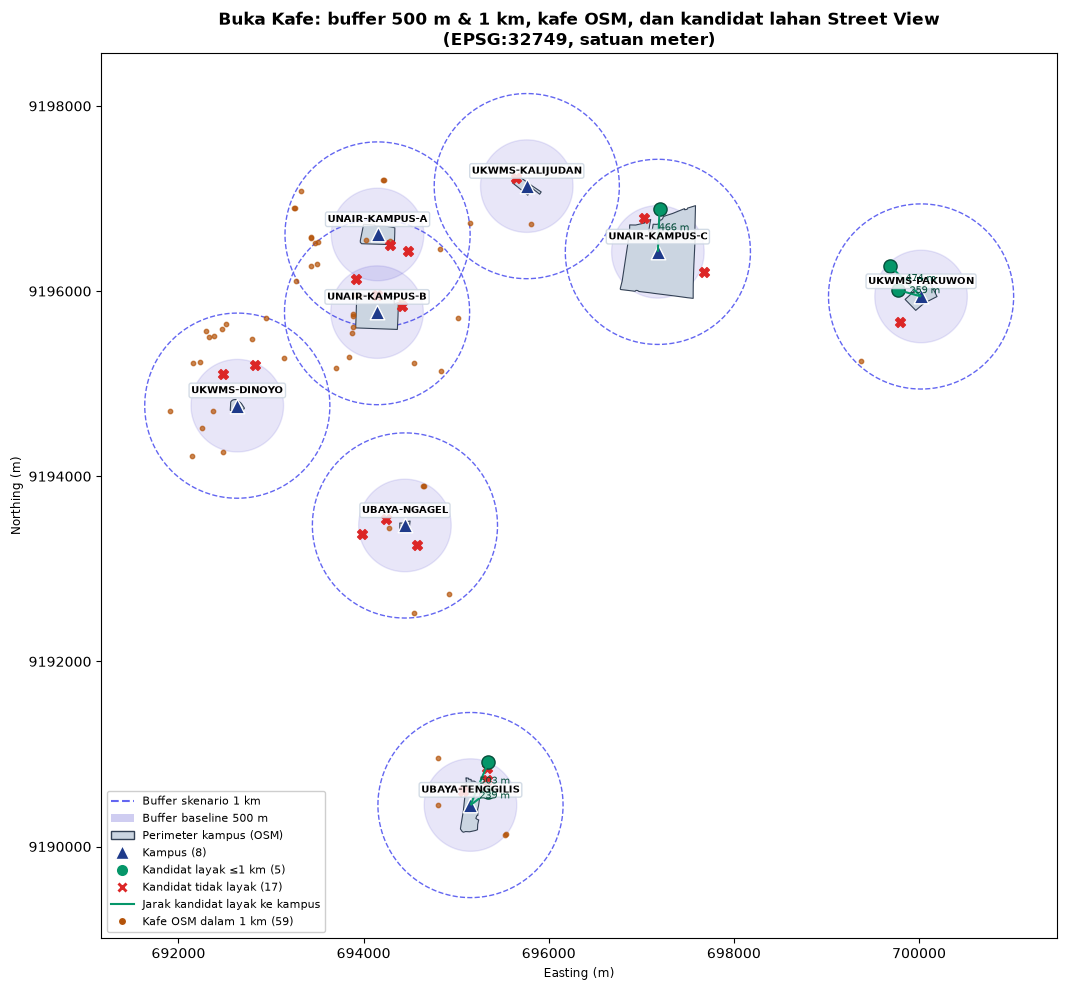

In [10]:
# Clipping: hanya kafe di dalam gabungan buffer 1 km yang digambar
area_1km = buffer_1000.dissolve()
kafe_terpotong = gpd.clip(kafe_m, area_1km)
print(f"Clipping: {len(kafe_m)} kafe -> {len(kafe_terpotong)} kafe di dalam area 1 km")

# Garis kandidat layak -> titik kampus terdekat
titik_kampus = kampus_m.set_index("id").geometry
layak = lahan_j[lahan_j["layak_1000m"]].copy()
garis = gpd.GeoDataFrame(
    {"id": layak["id_lahan"], "jarak": layak["jarak_kampus_m"]},
    geometry=[LineString([g, titik_kampus[k]]) for g, k in zip(layak.geometry, layak["id_kampus"])],
    crs=CRS_METRIK,
)

fig, ax = plt.subplots(figsize=(12, 10))
buffer_1000.plot(ax=ax, facecolor="none", edgecolor="#6366F1", linestyle="--", linewidth=1)
buffer_500.plot(ax=ax, facecolor="#4338CA", alpha=0.12, edgecolor="#4338CA", linewidth=1)
kampus_poly_m.plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155", linewidth=0.8)
kafe_terpotong.plot(ax=ax, color="#B45309", markersize=10, alpha=0.7)
garis.plot(ax=ax, color="#059669", linewidth=1.5)
lahan_j[~lahan_j["layak_1000m"]].plot(ax=ax, color="#DC2626", marker="X", markersize=50)
lahan_j[lahan_j["layak_1000m"]].plot(ax=ax, color="#059669", edgecolor="#064E3B", markersize=90)
kampus_m.plot(ax=ax, color="#1E3A8A", marker="^", markersize=110, edgecolor="white")

for _, k in kampus_m.iterrows():
    ax.annotate(k["id"], (k.geometry.x, k.geometry.y), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=7.5, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85, edgecolor="#CBD5E1"))
for _, g in garis.iterrows():
    tengah = g.geometry.interpolate(0.5, normalized=True)
    ax.annotate(f"{g['jarak']:.0f} m", (tengah.x, tengah.y), fontsize=7, color="#064E3B")

ax.legend(handles=[
    Line2D([0], [0], color="#6366F1", linestyle="--", label="Buffer skenario 1 km"),
    Patch(facecolor="#4338CA", alpha=0.25, label="Buffer baseline 500 m"),
    Patch(facecolor="#CBD5E1", edgecolor="#334155", label="Perimeter kampus (OSM)"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#1E3A8A", markersize=10, label=f"Kampus ({len(kampus_m)})"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#059669", markersize=9, label=f"Kandidat layak ≤1 km ({len(layak)})"),
    Line2D([0], [0], marker="X", color="w", markerfacecolor="#DC2626", markersize=9, label=f"Kandidat tidak layak ({len(lahan_j) - len(layak)})"),
    Line2D([0], [0], color="#059669", label="Jarak kandidat layak ke kampus"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#B45309", markersize=6, label=f"Kafe OSM dalam 1 km ({len(kafe_terpotong)})"),
], loc="lower left", fontsize=8, framealpha=0.95)
ax.set_title("Buka Kafe: buffer 500 m & 1 km, kafe OSM, dan kandidat lahan Street View\n(EPSG:32749, satuan meter)",
             fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.ticklabel_format(style="plain")
plt.tight_layout()
plt.savefig(ROOT / "notebooks" / "peta_geopandas.png", dpi=150)
plt.show()

## 8. Transformasi 2D dengan matriks homogen

Materi transformasi (translasi, rotasi, skala, komposit) diterapkan ke poligon kampus Ubaya Tenggilis. Setiap transformasi ditulis sebagai matriks 3×3 homogen, lalu dikalikan ke setiap titik poligon. Hasilnya dicocokkan dengan fungsi `shapely.affinity` untuk membuktikan perhitungannya benar.

Contoh komposit: **skala 1,5× terhadap titik tengah kampus**, yaitu translasi ke origin → skala → translasi balik:

Matriks skala komposit T(c) · S(1.5) · T(-c):
[[       1.5         0.    -347579.4 ]
 [       0.          1.5  -4595214.35]
 [       0.          0.          1.  ]]

Luas asli 8.79 ha -> setelah skala 1,5x: 19.78 ha (= 1,5² × asli)


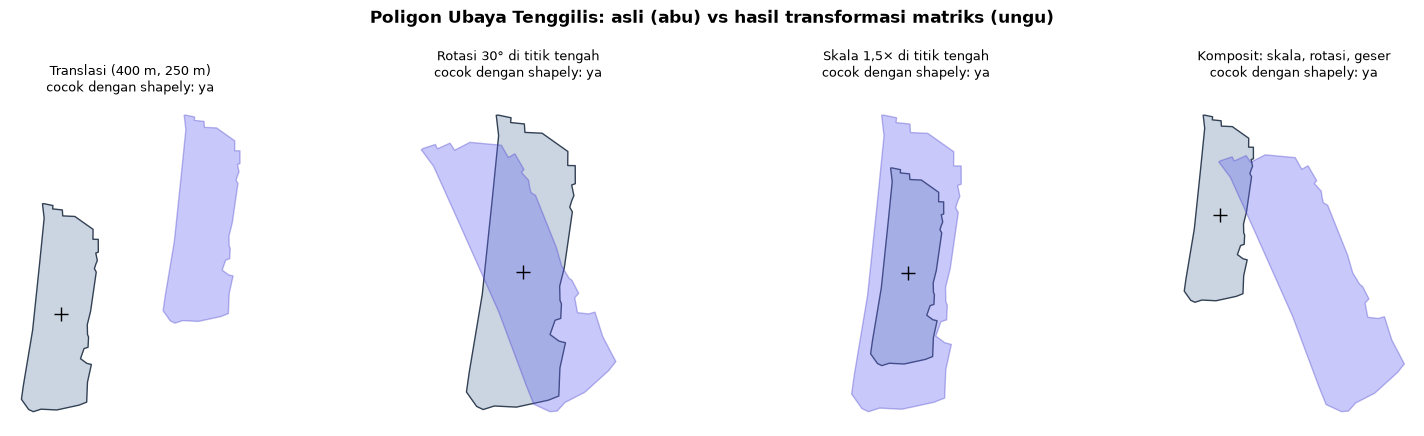

In [11]:
def T(tx, ty):
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=float)

def R(derajat):
    a = np.radians(derajat)
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])

def S(sx, sy):
    return np.array([[sx, 0, 0], [0, sy, 0], [0, 0, 1]], dtype=float)

def terapkan(M, poligon):
    # Titik (x, y) -> (x, y, 1), kalikan M, ambil (x', y')
    xy1 = np.c_[np.asarray(poligon.exterior.coords), np.ones(len(poligon.exterior.coords))]
    return Polygon((M @ xy1.T).T[:, :2])

asli = kampus_poly_m.set_index("id").loc["UBAYA-TENGGILIS", "geometry"]
cx, cy = asli.centroid.x, asli.centroid.y

M_translasi = T(400, 250)
M_rotasi = T(cx, cy) @ R(30) @ T(-cx, -cy)
M_skala = T(cx, cy) @ S(1.5, 1.5) @ T(-cx, -cy)
M_komposit = T(300, -200) @ M_rotasi @ M_skala      # skala -> rotasi -> geser

hasil = {
    "Translasi (400 m, 250 m)": (M_translasi, affinity.translate(asli, 400, 250)),
    "Rotasi 30° di titik tengah": (M_rotasi, affinity.rotate(asli, 30, origin=(cx, cy))),
    "Skala 1,5× di titik tengah": (M_skala, affinity.scale(asli, 1.5, 1.5, origin=(cx, cy))),
    "Komposit: skala, rotasi, geser": (
        M_komposit,
        affinity.translate(affinity.rotate(affinity.scale(asli, 1.5, 1.5, origin=(cx, cy)), 30, origin=(cx, cy)), 300, -200),
    ),
}

print("Matriks skala komposit T(c) · S(1.5) · T(-c):")
print(M_skala)
print(f"\nLuas asli {asli.area / 1e4:.2f} ha -> setelah skala 1,5x: {terapkan(M_skala, asli).area / 1e4:.2f} ha (= 1,5² × asli)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (judul, (M, cek_shapely)) in zip(axes, hasil.items()):
    manual = terapkan(M, asli)
    sama = manual.equals_exact(cek_shapely, tolerance=1e-6)
    gpd.GeoSeries([asli]).plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
    gpd.GeoSeries([manual]).plot(ax=ax, facecolor="#6366F1", alpha=0.35, edgecolor="#4338CA")
    ax.plot(cx, cy, "k+", markersize=10)
    ax.set_title(f"{judul}\ncocok dengan shapely: {'ya' if sama else 'tidak'}", fontsize=9)
    ax.set_aspect("equal")
    ax.axis("off")
fig.suptitle("Poligon Ubaya Tenggilis: asli (abu) vs hasil transformasi matriks (ungu)", fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Animasi: buffer yang membesar dari 0 sampai 1 km

Animasi `FuncAnimation` memperlihatkan buffer Ubaya Tenggilis membesar setiap 50 m. Kafe OSM dan kandidat lahan yang mulai masuk buffer berubah warna, dan penghitung di judul ikut bertambah. Garis putus-putus menandai batas baseline 500 m.

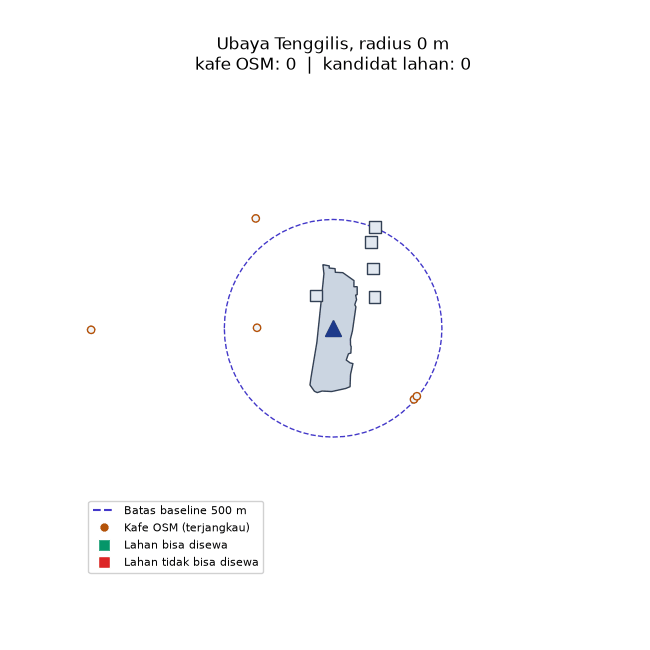

In [12]:
pusat = titik_kampus["UBAYA-TENGGILIS"]
area = pusat.buffer(SKENARIO_M + 150)
kafe_area = kafe_m[kafe_m.intersects(area)]
lahan_area = lahan_j[lahan_j.intersects(area)]
jarak_kafe = kafe_area.distance(pusat).to_numpy()
jarak_lahan = lahan_area.distance(pusat).to_numpy()
radius = list(range(0, SKENARIO_M + 1, 50))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
xmin, ymin, xmax, ymax = area.bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")
gpd.GeoSeries([pusat.buffer(BASELINE_M)]).plot(ax=ax, facecolor="none", edgecolor="#4338CA", linestyle="--")
kampus_poly_m[kampus_poly_m["id"] == "UBAYA-TENGGILIS"].plot(ax=ax, facecolor="#CBD5E1", edgecolor="#334155")
ax.plot(pusat.x, pusat.y, marker="^", color="#1E3A8A", markersize=12)
lingkaran = plt.Circle((pusat.x, pusat.y), 0, facecolor="#6366F1", alpha=0.18, edgecolor="#4338CA")
ax.add_patch(lingkaran)
titik_kafe = ax.scatter(kafe_area.geometry.x, kafe_area.geometry.y, s=28, c="#CBD5E1", edgecolors="#B45309", zorder=3)
titik_lahan = ax.scatter(lahan_area.geometry.x, lahan_area.geometry.y, s=70, marker="s", c="#E2E8F0", edgecolors="#334155", zorder=4)
ax.legend(handles=[
    Line2D([0], [0], color="#4338CA", linestyle="--", label="Batas baseline 500 m"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#B45309", markersize=7, label="Kafe OSM (terjangkau)"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#059669", markersize=8, label="Lahan bisa disewa"),
    Line2D([0], [0], marker="s", color="w", markerfacecolor="#DC2626", markersize=8, label="Lahan tidak bisa disewa"),
], loc="lower left", fontsize=8, framealpha=0.9)
judul = ax.set_title("")

def gambar(i):
    r = radius[i]
    lingkaran.set_radius(r)
    titik_kafe.set_facecolor(np.where(jarak_kafe <= r, "#B45309", "#F1F5F9"))
    titik_lahan.set_facecolor(np.where(jarak_lahan <= r, np.where(lahan_area["bisa_disewa"], "#059669", "#DC2626"), "#E2E8F0"))
    judul.set_text(f"Ubaya Tenggilis, radius {r} m\nkafe OSM: {(jarak_kafe <= r).sum()}  |  kandidat lahan: {(jarak_lahan <= r).sum()}")
    return lingkaran, titik_kafe, titik_lahan, judul

animasi = FuncAnimation(fig, gambar, frames=len(radius), interval=250, blit=False)
path_gif = ROOT / "notebooks" / "animasi_buffer.gif"
animasi.save(path_gif, writer=PillowWriter(fps=4))
plt.close(fig)
display(Image(filename=str(path_gif)))

## 10. Simpan hasil

In [13]:
per_kampus.to_csv(PROC / "geopandas_hasil_per_kampus.csv")
peringkat.drop(columns=[]).round(2).to_csv(PROC / "geopandas_peringkat_kandidat.csv", index_label="peringkat")

# Cek konsistensi dengan pipeline utama
pipeline = pd.read_csv(PROC / "hasil_per_kampus.csv").set_index("kampus_id")
cek = pd.DataFrame({
    "layak_500m (GeoPandas)": per_kampus["layak_500m"],
    "layak_500m (pipeline)": pipeline["layak_500m"],
    "kandidat_1000m (GeoPandas)": per_kampus["kandidat_1000m"],
    "kandidat_1000m (pipeline)": pipeline["kandidat_dalam_1000m"],
})
print("Tersimpan: data/processed/geopandas_hasil_per_kampus.csv, geopandas_peringkat_kandidat.csv, notebooks/peta_geopandas.png, notebooks/animasi_buffer.gif")
print("Hasil sama dengan pipeline:", bool((cek.iloc[:, 0] == cek.iloc[:, 1]).all() and (cek.iloc[:, 2] == cek.iloc[:, 3]).all()))
cek

Tersimpan: data/processed/geopandas_hasil_per_kampus.csv, geopandas_peringkat_kandidat.csv, notebooks/peta_geopandas.png, notebooks/animasi_buffer.gif
Hasil sama dengan pipeline: True


,layak_500m (GeoPandas),layak_500m (pipeline),kandidat_1000m (GeoPandas),kandidat_1000m (pipeline)
UNAIR-KAMPUS-A,0,0,2,2
UNAIR-KAMPUS-B,0,0,3,3
UNAIR-KAMPUS-C,1,1,3,3
UKWMS-DINOYO,0,0,2,2
UKWMS-KALIJUDAN,0,0,1,1
UKWMS-PAKUWON,2,2,3,3
UBAYA-NGAGEL,0,0,3,3
UBAYA-TENGGILIS,1,1,5,5


## 11. Keterbatasan

1. **Data lahan dari Google Street View.** 22 titik diobservasi lewat panorama Street View pada 1–2 November 2026, bukan survei fisik di lapangan. Tanggal citra 2024–2026, jadi kondisi sekarang bisa berbeda. Semua titik perlu ditinjau tim.
2. **Data sewa dan luas belum ada** untuk titik observasi. Komponen itu tidak ditebak, sehingga cakupan skor di bawah 60%.
3. **Gerbang kampus dan indikator mahasiswa belum teramati**; tipe jalan hanya diisi bila terlihat jelas di Street View.
4. **Jarak berupa garis lurus** dari titik kampus, bukan jarak tempuh lewat jalan.
5. **Kafe OSM bisa tidak lengkap**: kafe baru atau yang tutup mungkin belum tercatat di OpenStreetMap.
6. **Buffer kampus bisa bertumpuk** (misalnya Unair A dan B), sehingga satu kafe bisa terhitung di dua kampus pada tabel per kampus; total kafe unik dihitung terpisah.